# Oracle Construction — Phase Oracle — Qiskit Notebook

**Primitive:** Phase oracle (the standard building block used inside Grover's algorithm and
amplitude amplification) that marks a single target computational basis state with a `-1`
phase, leaving every other amplitude and every measurement probability unchanged.

## SETUP (must match the CUDA-Q notebook exactly)
| Parameter | Value |
|---|---|
| N_QUBITS | 3 |
| TARGET_INT | 6  (marked state, qubit 0 = LSB) |
| SHOTS | 10000 |
| SEED | 42 |
| QUBIT ORDERING CONTRACT | qubit 0 = **rightmost** bit in every printed bitstring (Qiskit's native convention — no reversal needed in this notebook) |
| GLOBAL PHASE CONVENTION | normalize so the first amplitude with `abs(amp) > 1e-9`, taken in ascending bitstring order, is rotated to be real and positive |
| Basis ordering for matrices | `{|000>, |001>, ..., |111>}` ascending binary order |

## Theory recap

A phase oracle for a target string `t` implements the diagonal unitary

`O_t |x> = -|x>`  if `x == t`,   `O_t |x> = +|x>`  otherwise

i.e. `O_t = I - 2|t><t|`, a diagonal matrix that is the identity everywhere except a single
`-1` on the diagonal entry corresponding to `|t>`. It is built from ordinary gates as
follows (this is the exact circuit — no oracle "black box" is used):

```
for each qubit q where bit q of TARGET_INT is 0:
    X(q)                       # temporarily flip so the marked pattern becomes all-ones
H(q_{n-1})
MCX(controls = q_0..q_{n-2}, target = q_{n-1})   # multi-controlled-X = Toffoli for n=3
H(q_{n-1})
for each qubit q where bit q of TARGET_INT is 0:
    X(q)                       # undo the temporary flip
```

The `H - MCX - H` sandwich around the last qubit is the standard trick that converts a
multi-controlled-X into a multi-controlled-Z (phase flip) using only Qiskit's native
Toffoli/`mcx` gate — `MCZ|1...1> = -|1...1>`, and the surrounding `X` gates remap the target
pattern `TARGET_INT` onto the all-ones pattern so the phase flip lands on the right state.

**Test harness:** to make the effect of the oracle visible, this notebook first prepares a
uniform superposition with `H` on every qubit, then applies the oracle above. Only steps 2-4
of the theory box are the oracle itself; the initial `H` layer and the final measurement are
test scaffolding, clearly marked in the circuit as separate stages.

**Important, verified-by-hand property:** since `O_t` is diagonal with entries `±1`, it never
changes any amplitude's *magnitude* — only its sign. Consequently the measured probability
distribution after the oracle is **uniform `1/8` for every outcome, identical to before the
oracle was applied**. This is not a bug; it is the defining property of a phase oracle (the
whole point of amplitude amplification is to use this invisible phase kick together with a
diffusion operator to make it visible in probabilities on a *later* step, which is outside
the scope of this notebook). This notebook verifies the sign flip directly in the exact
statevector (Cell 7), not in the histogram.

## Ordering-convention warning

Qiskit already indexes statevector amplitudes, `Operator` matrices, and measurement `counts`
keys with **qubit 0 as the least-significant (rightmost) bit** — no reversal is required in
this notebook. The CUDA-Q companion notebook indexes qubit 0 as the **most-significant
(leftmost) bit** internally and must explicitly reverse every bitstring to match this
convention.

**Run all cells top to bottom.**


In [1]:
# Install cell
# Exact package names: `qiskit` (core) + `qiskit-aer` (the high-performance simulator backend)
# + `pylatexenc` (needed by circuit.draw(output="mpl") to render gate labels).
# Tested against the current stable Qiskit 1.x / Aer 0.x release line.
!pip install -q qiskit qiskit-aer pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 45.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 52.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 2.0 MB/s eta 0:00:00


In [2]:
# Imports + constants
import numpy as np
from math import pi

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, Operator
import matplotlib.pyplot as plt

N_QUBITS = 3
TARGET_INT = 6   # marked basis state (qubit 0 = LSB)
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "phase_oracle"

print("N_QUBITS   =", N_QUBITS)
print("TARGET_INT =", TARGET_INT, "-> binary (q2 q1 q0) =", format(TARGET_INT, f'0{N_QUBITS}b'))
print("SHOTS      =", SHOTS)
print("SEED       =", SEED)


N_QUBITS   = 3
TARGET_INT = 6 -> binary (q2 q1 q0) = 110
SHOTS      = 10000
SEED       = 42


In [3]:
# Build the circuit gate-by-gate
qc = QuantumCircuit(N_QUBITS, name="PhaseOracleDemo")

# --- test harness stage 1: uniform superposition ---
for q in range(N_QUBITS):
    qc.h(q)  # equal superposition over all 2^N_QUBITS basis states, so the oracle's sign flip is visible

qc.barrier(label="oracle start")

# --- phase oracle marking TARGET_INT ---
zero_bit_qubits = [q for q in range(N_QUBITS) if not ((TARGET_INT >> q) & 1)]
for q in zero_bit_qubits:
    qc.x(q)  # temporarily remap the TARGET_INT pattern onto the all-ones pattern

qc.h(N_QUBITS - 1)  # H-MCX-H sandwich turns a multi-controlled-X into a multi-controlled-Z (phase flip)
qc.mcx(list(range(N_QUBITS - 1)), N_QUBITS - 1)  # multi-controlled-X (Toffoli for N_QUBITS=3): flips q_{n-1} only if all controls are |1>
qc.h(N_QUBITS - 1)

for q in zero_bit_qubits:
    qc.x(q)  # undo the temporary remap

qc.barrier(label="oracle end")

print(qc)
print("\nQubits X'd before/after the MCZ sandwich (bits of TARGET_INT equal to 0):", zero_bit_qubits)


     ┌───┐ oracle start ┌───┐     ┌───┐ oracle end 
q_0: ┤ H ├──────░───────┤ X ├──■──┤ X ├─────░──────
     ├───┤      ░       └───┘  │  └───┘     ░      
q_1: ┤ H ├──────░──────────────■────────────░──────
     ├───┤      ░       ┌───┐┌─┴─┐┌───┐     ░      
q_2: ┤ H ├──────░───────┤ H ├┤ X ├┤ H ├─────░──────
     └───┘      ░       └───┘└───┘└───┘     ░      

Qubits X'd before/after the MCZ sandwich (bits of TARGET_INT equal to 0): [0]


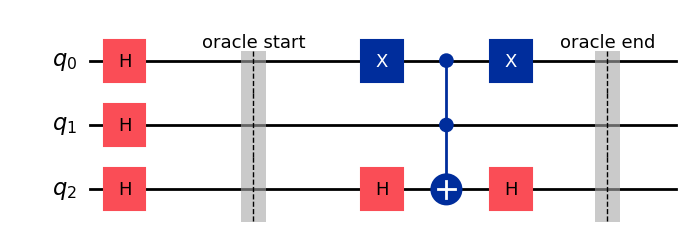

In [4]:
# Draw the circuit with matplotlib and save it
fig = qc.draw(output="mpl", style={"name": "iqp"})
fig.savefig(f"{TOPIC_SLUG}_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# Explicit matrix representation, built two independent ways, cross-checked

def h_matrix_full(n, q):
    # Full 2^n x 2^n matrix for H acting on qubit q (qiskit convention: qubit 0 = rightmost/LSB)
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        bit = (idx >> q) & 1
        idx0 = idx & ~(1 << q)
        idx1 = idx | (1 << q)
        if bit == 0:
            M[idx0, idx] += 1/np.sqrt(2)
            M[idx1, idx] += 1/np.sqrt(2)
        else:
            M[idx1, idx] += -1/np.sqrt(2)
            M[idx0, idx] += 1/np.sqrt(2)
    return M

def x_matrix_full(n, q):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        M[idx ^ (1 << q), idx] = 1
    return M

def mcx_matrix_full(n, controls, target):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        if all((idx >> c) & 1 for c in controls):
            M[idx ^ (1 << target), idx] = 1
        else:
            M[idx, idx] = 1
    return M

print("Single-qubit H matrix (any qubit), rounded to 4 decimals:")
print(np.round((1/np.sqrt(2)) * np.array([[1, 1], [1, -1]]), 4))

print("\nIdeal phase-oracle matrix O_t = I - 2|t><t| (diagonal, single -1 entry), basis |000>..|111>:")
ideal_diag = np.ones(2**N_QUBITS, dtype=complex)
ideal_diag[TARGET_INT] = -1
print(np.round(np.diag(ideal_diag), 4))

# (a) Hand-built full unitary of the ENTIRE circuit (H layer + oracle): multiply gate matrices in circuit order
U_hand = np.eye(2**N_QUBITS, dtype=complex)
for q in range(N_QUBITS):
    U_hand = h_matrix_full(N_QUBITS, q) @ U_hand
for q in zero_bit_qubits:
    U_hand = x_matrix_full(N_QUBITS, q) @ U_hand
U_hand = h_matrix_full(N_QUBITS, N_QUBITS - 1) @ U_hand
U_hand = mcx_matrix_full(N_QUBITS, list(range(N_QUBITS - 1)), N_QUBITS - 1) @ U_hand
U_hand = h_matrix_full(N_QUBITS, N_QUBITS - 1) @ U_hand
for q in zero_bit_qubits:
    U_hand = x_matrix_full(N_QUBITS, q) @ U_hand

# (b) Framework operator extraction (Qiskit's own Operator class from the circuit)
U_qiskit = Operator(qc).data

max_matrix_diff = np.max(np.abs(U_hand - U_qiskit))
print(f"\nMax |difference| between hand-built matrix and qiskit.quantum_info.Operator: {max_matrix_diff:.3e}")
assert max_matrix_diff < 1e-8, "Hand-built matrix and Qiskit Operator disagree!"
print("Full 8x8 unitary matrices MATCH (both methods agree).")

# Also isolate and verify JUST the oracle sub-block matches the ideal diagonal (up to the H-layer basis change)
U_oracle_only = np.eye(2**N_QUBITS, dtype=complex)
for q in zero_bit_qubits:
    U_oracle_only = x_matrix_full(N_QUBITS, q) @ U_oracle_only
U_oracle_only = h_matrix_full(N_QUBITS, N_QUBITS - 1) @ U_oracle_only
U_oracle_only = mcx_matrix_full(N_QUBITS, list(range(N_QUBITS - 1)), N_QUBITS - 1) @ U_oracle_only
U_oracle_only = h_matrix_full(N_QUBITS, N_QUBITS - 1) @ U_oracle_only
for q in zero_bit_qubits:
    U_oracle_only = x_matrix_full(N_QUBITS, q) @ U_oracle_only

max_oracle_diff = np.max(np.abs(U_oracle_only - np.diag(ideal_diag)))
print(f"Max |difference| between oracle-only matrix and ideal diag(+1,...,-1,...,+1): {max_oracle_diff:.3e}")
assert max_oracle_diff < 1e-8, "Oracle sub-circuit does not match the ideal phase-flip matrix!"
print("Oracle-only matrix MATCHES the ideal diagonal phase-flip operator.")


Single-qubit H matrix (any qubit), rounded to 4 decimals:
[[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]

Ideal phase-oracle matrix O_t = I - 2|t><t| (diagonal, single -1 entry), basis |000>..|111>:
[[ 1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  1.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  1.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j -1.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  1.+0.j]]

Max |difference| between hand-built matrix and qiskit.quantum_info.Operator: 0.000e+00
Full 8x8 unitary matrices MATCH (both methods agree).
Max |difference| between oracle-only matrix and ideal diag(+1,...,-1,...,+1): 2.220e-16
Oracle-only matrix MATCHES the ideal diago

In [6]:
# Exact statevector: extract, apply global-phase normalization, print amplitudes + probabilities
qc_state_only = QuantumCircuit(N_QUBITS)
qc_state_only.compose(qc, inplace=True)  # same gates, no measurements yet

sv = Statevector.from_instruction(qc_state_only)
amps = sv.data.copy()

# GLOBAL PHASE CONVENTION: first amplitude with abs(amp) > 1e-9, ascending bitstring order, made real & positive
for idx in range(len(amps)):
    if abs(amps[idx]) > 1e-9:
        phase = np.angle(amps[idx])
        amps = amps * np.exp(-1j*phase)
        break

print("Qiskit convention: qubit 0 = rightmost bit -> NO reversal needed for these amplitudes.\n")
print(f"{'bitstring':10s} {'amplitude':22s} {'probability':12s}")
QISKIT_PROBS_EXACT = {}
for idx in range(2**N_QUBITS):
    bitstring = format(idx, f'0{N_QUBITS}b')
    amp = amps[idx]
    prob = abs(amp)**2
    QISKIT_PROBS_EXACT[bitstring] = prob
    marker = "  <-- marked state (sign flipped)" if idx == TARGET_INT else ""
    print(f"|{bitstring}>   {amp.real:+.6f}{amp.imag:+.6f}j    {prob:.6f}{marker}")

print("\nProbabilities sum to:", sum(QISKIT_PROBS_EXACT.values()))


Qiskit convention: qubit 0 = rightmost bit -> NO reversal needed for these amplitudes.

bitstring  amplitude              probability 
|000>   +0.353553+0.000000j    0.125000
|001>   +0.353553+0.000000j    0.125000
|010>   +0.353553+0.000000j    0.125000
|011>   +0.353553+0.000000j    0.125000
|100>   +0.353553+0.000000j    0.125000
|101>   +0.353553+0.000000j    0.125000
|110>   -0.353553+0.000000j    0.125000  <-- marked state (sign flipped)
|111>   +0.353553+0.000000j    0.125000

Probabilities sum to: 0.9999999999999992


### Ordering-fix note (Qiskit)

**No bit reversal was applied in this notebook.** Qiskit's `Statevector`, `Operator`, and
measurement `counts` all natively index qubit 0 as the least-significant (rightmost) bit of
every printed bitstring — this already matches the QUBIT ORDERING CONTRACT declared in the
setup, so the amplitudes and probabilities above are used as-is.

Contrast this with the CUDA-Q notebook, where `cudaq.get_state()` and `cudaq.sample()` index
qubit 0 as the *most-significant* (leftmost) bit, requiring an explicit reversal step before
its results can be compared to this notebook's.


In [7]:
# Measurement: add measurements, sample with the shared SEED/SHOTS, get counts -> probabilities
qc_meas = QuantumCircuit(N_QUBITS, N_QUBITS)
qc_meas.compose(qc, inplace=True)
qc_meas.measure(range(N_QUBITS), range(N_QUBITS))

sim = AerSimulator(seed_simulator=SEED)
qc_meas_t = transpile(qc_meas, sim)
job = sim.run(qc_meas_t, shots=SHOTS, seed_simulator=SEED)
counts = job.result().get_counts()

# counts keys are already in "qubit 0 = rightmost" format -> no reordering needed
QISKIT_PROBS_SAMPLED = {format(idx, f'0{N_QUBITS}b'): 0.0 for idx in range(2**N_QUBITS)}
for bitstring, count in counts.items():
    QISKIT_PROBS_SAMPLED[bitstring] = count / SHOTS

print("Sampled probabilities (from", SHOTS, "shots, seed =", SEED, "):")
for bitstring in sorted(QISKIT_PROBS_SAMPLED):
    print(f"|{bitstring}>   {QISKIT_PROBS_SAMPLED[bitstring]:.4f}")


Sampled probabilities (from 10000 shots, seed = 42 ):
|000>   0.1256
|001>   0.1199
|010>   0.1226
|011>   0.1240
|100>   0.1278
|101>   0.1296
|110>   0.1277
|111>   0.1228


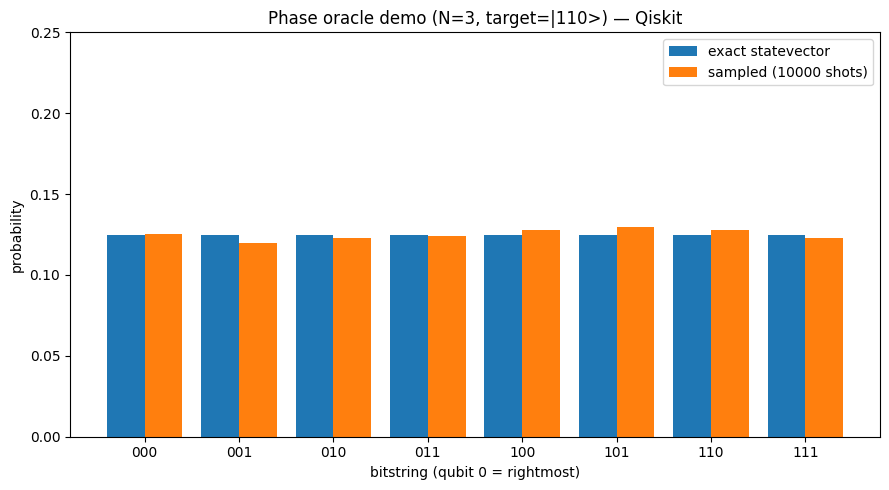

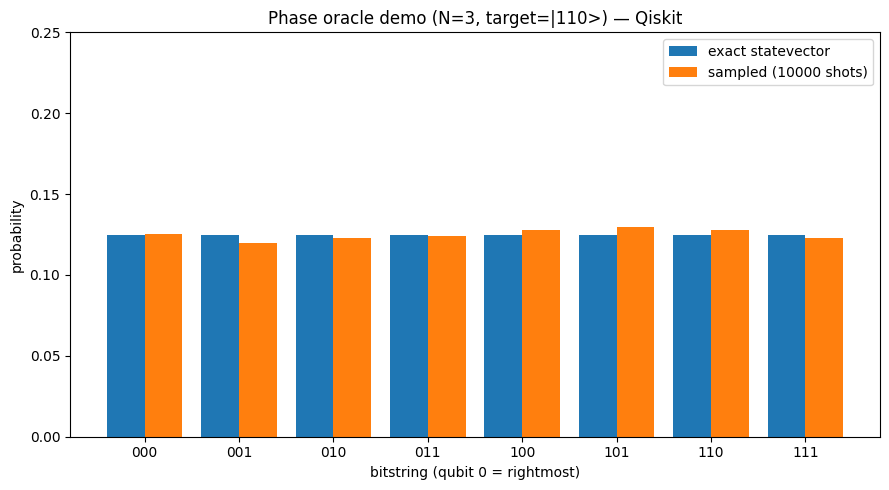

In [8]:
# Histogram: matplotlib bar chart, saved to file
bitstrings_sorted = sorted(QISKIT_PROBS_EXACT.keys())
exact_vals = [QISKIT_PROBS_EXACT[b] for b in bitstrings_sorted]
sampled_vals = [QISKIT_PROBS_SAMPLED[b] for b in bitstrings_sorted]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(bitstrings_sorted))
width = 0.4
ax.bar(x - width/2, exact_vals, width, label="exact statevector", color="#1f77b4")
ax.bar(x + width/2, sampled_vals, width, label=f"sampled ({SHOTS} shots)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(bitstrings_sorted, rotation=0)
ax.set_xlabel("bitstring (qubit 0 = rightmost)")
ax.set_ylabel("probability")
ax.set_title(f"Phase oracle demo (N={N_QUBITS}, target=|{format(TARGET_INT, f'0{N_QUBITS}b')}>) — Qiskit")
ax.set_ylim(0, 0.25)
ax.legend()
fig.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_qiskit_histogram.png", dpi=150, bbox_inches="tight")
fig


In [9]:
# Resource counts
print("Circuit depth:", qc.depth())
print("Gate counts:", dict(qc.count_ops()))


Circuit depth: 4
Gate counts: {'h': 5, 'barrier': 2, 'x': 2, 'ccx': 1}


### Convention notes (plain text summary)

- **Bit-order convention:** qubit 0 = rightmost character of every bitstring. Qiskit uses
  this natively; **no reversal applied** in this notebook.
- **Global phase convention:** the exact statevector was multiplied by `exp(-i*phase)` where
  `phase` is the angle of the first amplitude (ascending bitstring order) with magnitude
  `> 1e-9`, so that amplitude is real and positive.
- **Basis ordering for all matrices:** ascending binary order `|000> ... |111>`.
- **Why the histogram looks flat:** a phase oracle is a diagonal `±1` matrix — it cannot
  change any amplitude's magnitude, only its sign, so probabilities before and after the
  oracle are identical (`1/8` each here). The oracle's effect is verified directly in the
  statevector sign flip (Cell 6), not in the histogram.


In [10]:
# Final result: exact-statevector-derived probability dictionary
# (used for the cross-notebook diff-check, since it is deterministic and RNG-independent --
#  unlike the finite-shot counts, which depend on each framework's own internal RNG stream
#  and will NOT exactly agree bit-for-bit even with a matching SEED value)
QISKIT_RESULT = {b: QISKIT_PROBS_EXACT[b] for b in sorted(QISKIT_PROBS_EXACT)}
print("QISKIT_RESULT =")
for b, p in QISKIT_RESULT.items():
    print(f"  '{b}': {p:.6f}")


QISKIT_RESULT =
  '000': 0.125000
  '001': 0.125000
  '010': 0.125000
  '011': 0.125000
  '100': 0.125000
  '101': 0.125000
  '110': 0.125000
  '111': 0.125000


In [11]:
# Diff-check block (run AFTER also running the CUDA-Q notebook and pasting its CUDAQ_RESULT below)
# Hand-computed expected result for sanity-checking: a phase oracle applied after a uniform
# superposition always yields a perfectly uniform probability distribution.
HAND_COMPUTED_EXPECTED = {format(i, f'0{N_QUBITS}b'): 1/(2**N_QUBITS) for i in range(2**N_QUBITS)}
max_delta_vs_hand = max(abs(QISKIT_RESULT[b] - HAND_COMPUTED_EXPECTED[b]) for b in QISKIT_RESULT)
print("Max delta between QISKIT_RESULT and hand-computed expected (uniform 1/8):", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-3

# CUDAQ_RESULT = { ... }  # <- paste the dict printed at the end of the CUDA-Q notebook here
# max_delta = max(abs(QISKIT_RESULT[b] - CUDAQ_RESULT[b]) for b in QISKIT_RESULT)
# print("Max probability delta between QISKIT_RESULT and CUDAQ_RESULT:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q phase-oracle results disagree beyond tolerance!"


Max delta between QISKIT_RESULT and hand-computed expected (uniform 1/8): 9.71445146547012e-17
